<a href="https://colab.research.google.com/github/Timoteogon/Calculo-de-probabilidad-de-impacto-de-NEA/blob/main/Calculo_de_probabilidad_de_impacto_de_NEA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Calculo de probabilidad de impacto de un NEA

## Resumen

- **NEA:** 29075 (1950 DA), clase Apolo. Posible encuentro con la Tierra en marzo de 2880.
- **Metodo:** covarianza de SBDB (7x7, con $A_2$), integracion con ASSIST (DE441) y plano B con linealizacion; $P_i$ como la integral de una gaussiana sobre el disco de radio $R_{\rm ef}$.
- **Resultado:** $P_i\approx2.9\times10^{-4}$ (linealizado desde la solucion de impacto), frente a $3.4\times10^{-4}$ de Sentry. Escala de Palermo $\approx-0.95$.
- **Advertencia:** el resultado depende del punto donde se linealiza. Con el nominal integrado como centro da $0$, y linealizando en otros puntos del barrido de $A_2$ ($z=0,\ 0.5,\ 1.0$) da entre $2\times10^{-65}$ y $3\times10^{-14}$, frente a $2.9\times10^{-4}$ en la solucion de impacto ($z=1.647$). Por eso ese valor se toma como el del punto mas cercano a la region de impacto y no como una estimacion validada. Al final se agrega un chequeo de la linealizacion y una prueba de sensibilidad a $d_{\rm ref}$.


### Instalamos librerias

In [ ]:
!pip install -Uq pymcel "rebound==4.6.0" assist naif-de440 jpl-small-bodies-de441-n16

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


### Importamos librerias

In [ ]:
import pymcel as pc
import numpy as np
import matplotlib.pyplot as plt
import rebound as rb
import spiceypy as spy
import requests
from astropy.time import Time
import assist

Bienvenido a PyMCel v0.9.25 ¡al infinito y más allá!


### Constantes

In [ ]:
# conversor grados<->radianes
deg = np.pi / 180
rad = 180 / np.pi

# constantes
mu = pc.constantes.mu_sun
AU = pc.constantes.au

# mu en UA^3/s^2 (mu viene en m^3/s^2 y AU en m)
mu_ua = mu/AU**3

# factor para pasar de UA/s a km/s
factor = AU/1000

# megatones en joules
MT_J = 4.184e+15

# fecha estandar en astronomia
J2000 = "2000-01-01 12:00:00"

# segundos en un dia
dia = pc.constantes.dia

# velocidad de escape de la tierra en km/s (nasa earth fact sheet: https://nssdc.gsfc.nasa.gov/planetary/factsheet/earthfact.html)
v_esc = 11.19

# probabilidad de impacto de sentry (jpl) para 29075: https://cneos.jpl.nasa.gov/sentry/details.html#?des=29075
P_sentry = 3.4e-4

# NEA elegido

## 29075 (1950 DA) - clase Apollo

Datos del NEA necesarios para el analisis

Los elementos orbitales son los publicados por la SBDB de JPL (https://ssd.jpl.nasa.gov/tools/sbdb_lookup.html#/?sstr=29075), epoca JD 2461200.5.

In [ ]:
# los elementos son osculantes a la epoca JPL 285 (2461200.5, 2026-Jun-09.0 TDB), referidos a la ecliptica J2000.
e = 0.507568426265487
a = 1.698452772804431    # UA
q = 0.836371771825833    # UA
inc = 12.15583902281257 * deg
node = 356.5443018677842 * deg
peri = 224.8228664081709 * deg

# incertidumbres 1-sigma
sigma_e = 1.1687e-8
sigma_a = 1.0037e-9    # UA
sigma_q = 2.0114e-8    # UA

sigma_i = 2.6134e-7 * deg
sigma_M = 2.1423e-6 * deg
sigma_node = 3.4554e-6 * deg
sigma_peri = 5.4834e-6 * deg

# semilatus rectum (parametro de la conica), en UA
p = q*(1+e)

# parametros fisicos de 1950 DA

H = 17.28    # magnitud absoluta

# diametro
D = 1.3           # km
sigma_D = 0.13    # km

# periodo de rotacion
P_rot = 2.1216    # horas

albedo = 0.070
sigma_albedo = 0.020

# densidad
d = 2.2 # g/cm^3

# Matriz de covarianza de los parametros orbitales

Se descarga de la API de SBDB (JPL) la solucion orbital de 1950 DA con su matriz de covarianza. Los parametros estan en el orden **e, q, tp, node, peri, i, A2**, y la matriz corresponde a la epoca JD 2458929.5 (2020-03-21), que es distinta de la epoca de los elementos de la celda anterior (JD 2461200.5, 2026-06-09). Comparando con las incertidumbres publicadas de los elementos (misma API), las unidades son: $q$ en UA, $t_p$ en dias, los angulos en grados y $e$ adimensional.

In [ ]:
url = "https://ssd-api.jpl.nasa.gov/sbdb.api"

params = {
    "sstr": "29075",
    "cov": "mat",
    "full-prec": "true"
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

datos = response.json()

# extraer covarianza
cov_data = datos["orbit"]["covariance"]

cov = np.array(cov_data["data"], dtype=float)
labels = cov_data["labels"]
epoch_cov = float(cov_data["epoch"])

print("Asteroide:", datos["object"]["fullname"])
print("Dimensiones:", cov.shape)
print("Parametros:", labels)
print("Epoca:", epoch_cov)
print("Matriz de covarianza:\n", cov)

Asteroide: 29075 (1950 DA)
Dimensiones: (7, 7)
Parametros: ['e', 'q', 'tp', 'node', 'peri', 'i', 'A2']
Epoca: 2458929.5
Matriz de covarianza:
 [[ 1.37014829e-16 -2.35238720e-16 -2.71405468e-14  3.58771041e-14
  -4.49514416e-14 -6.84971433e-16 -4.48885280e-24]
 [-2.35238720e-16  4.03967640e-16  4.72212874e-14 -6.18495673e-14
   7.77759031e-14  1.17737533e-15  7.99133403e-24]
 [-2.71405468e-14  4.72212874e-14  1.16638254e-11 -1.05349932e-11
   1.76106446e-11 -5.98743332e-15  2.66402437e-21]
 [ 3.58771041e-14 -6.18495673e-14 -1.05349932e-11  1.19004581e-11
  -1.77785638e-11 -9.60184372e-14 -1.77364840e-21]
 [-4.49514416e-14  7.77759031e-14  1.76106446e-11 -1.77785638e-11
   2.99201405e-11 -6.99769864e-14  2.89147277e-21]
 [-6.84971433e-16  1.17737533e-15 -5.98743332e-15 -9.60184372e-14
  -6.99769864e-14  6.82336230e-14  4.38791024e-23]
 [-4.48885280e-24  7.99133403e-24  2.66402437e-21 -1.77364840e-21
   2.89147277e-21  4.38791024e-23  1.07967527e-30]]


La funcion **requests.get()** hace una peticion a una pagina o API de internet. Con **raise_for_status()** se genera un error si el servidor respondio con un fallo, y **json()** convierte la respuesta en un diccionario de Python.

ejemplo:

```python
import requests

respuesta = requests.get("https://ssd-api.jpl.nasa.gov/sbdb.api", params={"sstr": "29075"}, timeout=30)
respuesta.raise_for_status()   # error si la respuesta no fue exitosa
datos = respuesta.json()       # diccionario de Python
```

### Comprobaciones de la covarianza

Se verifica que la matriz sea simetrica, se obtienen las incertidumbres $\sigma_i=\sqrt{C_{ii}}$ de la diagonal y se comprueba que sea definida positiva (autovalores positivos y factorizacion de Cholesky posible), condicion necesaria para generar muestras con $x_k=x_0+L\,z_k$.

Los autovalores de $C$ abarcan muchos ordenes de magnitud porque los parametros tienen escalas muy distintas (por ejemplo, $\sigma_{A_2}\sim10^{-15}$ frente a $\sigma_{t_p}\sim10^{-6}$).

In [ ]:
# comprobaciones
print("Simetrica:", np.allclose(cov, cov.T))
print("Dimension:", cov.shape)

# incertidumbres derivadas de la diagonal
sigma = np.sqrt(np.diag(cov))

print(labels)
print(sigma)

Simetrica: True
Dimension: (7, 7)
['e', 'q', 'tp', 'node', 'peri', 'i', 'A2']
[1.17053334e-08 2.00989462e-08 3.41523431e-06 3.44970406e-06
 5.46993058e-06 2.61215664e-07 1.03907424e-15]


La funcion **np.allclose()** compara dos arreglos y dice si son iguales dentro de una tolerancia pequena. Sirve porque con numeros decimales una igualdad exacta casi nunca se cumple.

ejemplo:

```python
0.1 + 0.2 == 0.3               # False
np.allclose(0.1 + 0.2, 0.3)    # True
```

### Autovalores y factorizacion de Cholesky

Se calculan los autovalores de $C$ (todos deben ser positivos) y se factoriza con Cholesky, $C=LL^T$. Si $C$ no fuera definida positiva, **np.linalg.cholesky** daria un error.

In [ ]:
# autovalores de la matriz
autovalores = np.linalg.eigvalsh(cov)
print("Autovalores:")
print(autovalores)
print(autovalores.min() > 0)

# factorizacion de cholesky (da error si cov no es definida positiva)
L = np.linalg.cholesky(cov)

Autovalores:
[2.69634179e-34 5.94808731e-22 2.33738910e-17 5.23823837e-14
 8.18377337e-13 1.25185455e-12 5.14305610e-11]
True


La funcion **np.linalg.eigvalsh()** calcula los autovalores de una matriz simetrica (la **h** es por hermitiana, que en matrices reales significa simetrica).

ejemplo:

```python
A = np.array([[2., 0.],
              [0., 3.]])

np.linalg.eigvalsh(A)    # array([2., 3.])
```

La funcion **np.linalg.cholesky()** factoriza una matriz definida positiva $C$ como $C=LL^T$, con $L$ triangular inferior. Da error si la matriz no es definida positiva.

ejemplo:

```python
C = np.array([[4., 2.],
              [2., 3.]])

L = np.linalg.cholesky(C)
np.allclose(L @ L.T, C)    # True
```

## Escala de Palermo

Es una escala continua y logaritmica, de uso tecnico entre especialistas (Chesley et al., 2002). Compara el riesgo de un objeto concreto con el riesgo de fondo: la probabilidad de que, en el mismo intervalo de tiempo, la Tierra reciba un impacto de igual o mayor energia por azar.

$$PS = \log_{10}\!\left(\frac{P_i}{f_B\,\Delta T}\right)$$

donde:

- $P_i$ es la probabilidad de impacto del evento,
- $\Delta T$ es el tiempo (en años) hasta el posible impacto,
- $f_B$ es la frecuencia anual de fondo de impactos con energia $\ge E$, modelada como

$$f_B = 0.03\,E^{-0.8}\ \text{año}^{-1}$$

con $E$ la energia del impacto en megatones de TNT.

**Interpretacion:**

- $PS < -2$: sin motivo de preocupacion.
- $-2 \le PS < 0$: merece monitoreo cuidadoso.
- $PS \ge 0$: el riesgo iguala o supera el de fondo; merece atencion seria.

Cuando un objeto tiene varias soluciones virtuales de impacto, se suma:

$$PS_{\rm acum} = \log_{10}\!\left(\sum_i 10^{PS_i}\right)$$

Sentry y NEODyS reportan la Palermo acumulada y la maxima.

In [ ]:
def frecuencia_fondo(E):
    fb = 0.03*E**(-0.8)
    return fb

def palermo(Pi, DeltaT, E):
    PS = np.log10(Pi/(frecuencia_fondo(E) * DeltaT))
    return PS

def acumulado(PSi):
    PS_acum = np.log10(np.sum(10**np.asarray(PSi)))
    return PS_acum

def interpretacion(PS):
    if PS < -2:
        print("sin motivo de preocupacion")
    if -2 <= PS < 0:
        print("merece monitoreo cuidadoso")
    if 0 <= PS:
        print("el riesgo iguala o supera el de fondo; merece atencion seria")

La funcion **np.asarray()** se utiliza para convertir la entrada en un arreglo de NumPy, reutilizando el arreglo existente si la entrada ya es un **ndarray** (a diferencia de **np.array()**, que siempre crea una copia).

ejemplo:

```python
import numpy as np

# Una lista de Python normal
lista = [1, 2, 3]

# Convertir la lista en un arreglo de NumPy
resultado = np.asarray(lista)

print(resultado)
print(type(resultado))
```

# Velocidad de impacto del NEA

La energia del impacto depende de la velocidad con la que el asteroide llega a la Tierra, no de su velocidad heliocentrica. Para obtenerla se pasa de elementos orbitales a vector de estado en el punto donde el asteroide podria coincidir con la Tierra.

1. Puntos de encuentro: los nodos

Para que haya impacto, el asteroide debe estar a $r\approx 1$ UA y en el plano de la ecliptica ($z=0$). Eso solo ocurre en los nodos de su orbita:

$$f_{\rm asc}=-\omega, \qquad f_{\rm desc}=\pi-\omega$$

En cada nodo:

$$r=\frac{p}{1+e\cos f}, \qquad p=q(1+e)$$

El nodo con $r$ mas cercano a 1 UA es el relevante. La diferencia $|r_{\rm nodo}-1|$ esta relacionada con el MOID.

2. Posicion y velocidad en el sistema perifocal
$$\vec r_q=r\,(\cos f,\ \sin f,\ 0)$$ \
$$\vec v_q=\sqrt{\frac{\mu}{p}}\,\big(-\sin f,\ e+\cos f,\ 0\big)$$
3. Rotacion al sistema astronomico

Se usa la misma matriz de rotacion que para la posicion:

$$M = R_3(-\Omega)\,R_1(-i)\,R_3(-\omega)$$\
$$\vec r = M\,\vec r_q, \qquad \vec v = M\,\vec v_q$$
4. Velocidad de la Tierra

Se supone orbita circular a 1 UA en el plano de la ecliptica. Su velocidad es $\sqrt{\mu/1\,\text{UA}}$, con direccion tangencial:

$$\vec v_\oplus=\sqrt{\mu}\,\frac{(-y,\ x,\ 0)}{\sqrt{x^2+y^2}}$$
5. Velocidad relativa y velocidad de impacto

La resta es vectorial:

$$\vec v_\infty=\vec v-\vec v_\oplus, \qquad v_\infty=|\vec v_\infty|$$ \
$$v_{\rm imp}=\sqrt{v_\infty^2+v_{\rm esc}^2}, \qquad v_{\rm esc}\approx 11.19\ \text{km/s}$$

In [ ]:
for f in [-peri, np.pi - peri]:
    # coordenadas en el sistema perifocal
    r = p / (1 + e*np.cos(f))
    xq = r*np.cos(f)
    yq = r*np.sin(f)
    zq = 0

    # velocidad en el sistema perifocal
    vxq = -np.sqrt(mu_ua/p)*np.sin(f)
    vyq = np.sqrt(mu_ua/p)*(e + np.cos(f))
    vzq = 0

    # matriz de rotacion
    M = spy.eul2m(-node, -inc, -peri, 3, 1, 3)

    # coordenadas y velocidad en el sistema astronomico (ecliptica J2000)
    rq_vec = np.array([xq, yq, zq])
    vq_vec = np.array([vxq, vyq, vzq])
    r_vec = spy.mxv(M, rq_vec)
    v_vec = spy.mxv(M, vq_vec)

    x, y, z = r_vec

    # velocidad de la Tierra (circular, 1 UA, plano de la ecliptica)
    v_tierra = np.sqrt(mu_ua)*np.array([-y, x, 0])/np.sqrt(x**2 + y**2)

    # velocidad relativa y de impacto
    v_inf = np.sqrt(np.sum((v_vec - v_tierra)**2))*factor
    v_imp = np.sqrt(v_inf**2 + v_esc**2)

    print(f"distancia al Sol en el nodo: {r:.3e}, velocidad relativa a la Tierra: {v_inf:.3e}, velocidad de impacto: {v_imp:.3e}")

distancia al Sol en el nodo: 1.970e+00, velocidad relativa a la Tierra: 1.664e+01, velocidad de impacto: 2.005e+01
distancia al Sol en el nodo: 9.271e-01, velocidad relativa a la Tierra: 1.333e+01, velocidad de impacto: 1.741e+01


# Energia de impacto

$$E=\tfrac12\,m\,v_{\rm imp}^2$$

In [ ]:
def energia_de_impacto(m, v_imp):
    E = 1/2 * m * v_imp**2
    return E

# Masa del NEA

Se supone un cuerpo esferico de diametro $D$ y densidad $\rho$:

$$m=\rho\,\frac{4}{3}\pi\left(\frac{D}{2}\right)^3$$

con $D=1.3$ km y $\rho=2.2$ g/cm³. La densidad se toma de Ward y Asphaug (2003), que usan 2.2 g/cm$^3$ como composicion rocosa nominal, y, junto con el diametro ($\pm0.13$ km, que da cerca de $\pm30\,\%$ en la masa), es la mayor fuente de incertidumbre de la energia.

In [ ]:
# radio en m
r = D/2 * 1000

# volumen en m^3
v = 4/3 * np.pi * r **3

# masa en kg
m = d*1000 * v

print(f"m = {m:.3e} kg")

m = 2.531e+12 kg


# Calculo de la energia de impacto

Se usa la velocidad de impacto del nodo relevante (el de $r\approx1$ UA), pasada a m/s, y la energia se convierte a megatones de TNT (1 Mt $=4.184\times10^{15}$ J).

In [ ]:
# velocidad de impacto en m/s (la del nodo descendente, r = 0.927 UA, ultima de la celda anterior)
v_imp_ms = v_imp*1000

# energia de impacto
E_imp = energia_de_impacto(m, v_imp_ms)

# energia en megatones
E_MT = E_imp / MT_J

print(f"E = {E_imp:.3e} J = {E_MT:.3e} Mt")

E = 3.834e+20 J = 9.165e+04 Mt


# Se halla la frecuencia anual de fondo de impactos

Con la energia en megatones se calcula $f_B=0.03\,E^{-0.8}$ (impactos por año con energia mayor o igual a $E$), que se necesita para la escala de Palermo.

In [ ]:
fb = frecuencia_fondo(E_MT)

print(f"La frecuencia anual de fondo de impactos es de {fb}")

La frecuencia anual de fondo de impactos es de 3.2168666824665548e-06


# Probabilidad de impacto $P_i$

La orbita del NEA se conoce con incertidumbre, que esta en la matriz de covarianza $C$ ($7\times7$, con $A_2$) que se baja de SBDB. Con $P_i\sim10^{-4}$, un muestreo aleatorio necesitaria demasiadas integraciones de 854 años para ver unos pocos impactos, asi que se usa el metodo del plano B con linealizacion, que es el que se usa en el monitoreo de impactos.

### 1. Solucion de impacto

El nominal $x_0$ no impacta: pasa a $1.0\times10^{7}$ km de la Tierra en 2880. Como $A_2$ es la incertidumbre que mas desplaza la posicion en 2880 (ver la seccion de Yarkovsky), se barre $A_2$ de $-3\sigma$ a $+3\sigma$, con los otros seis elementos fijos en el nominal, hasta encontrar un asteroide virtual que impacte, $x_{\rm imp}$.

### 2. Plano B

Para $x_{\rm imp}$ se integra con ASSIST (efemerides DE441, fuerzas no gravitacionales incluidas) hasta el encuentro de 2880 y se calcula la posicion $\vec b$ del asteroide en el plano B, perpendicular a la velocidad relativa de llegada. Hay impacto si $|\vec b|<R_{\rm ef}$, con

$$R_{\rm ef}=R_\oplus\sqrt{1+\frac{v_{\rm esc}^2}{v_\infty^2}}$$

donde $R_\oplus=6371$ km, $v_{\rm esc}\approx11.19$ km/s y $v_\infty$ es la velocidad relativa de llegada del encuentro de 2880.

### 3. Linealizacion y covarianza en el plano B

Cerca de $x_{\rm imp}$ se aproxima $\vec b$ como lineal en los 7 elementos, con el Jacobiano $J$ calculado por diferencias centradas (14 integraciones). La covarianza de los elementos se lleva al plano B como

$$\Gamma=J\,C\,J^T$$

### 4. Estimacion de $P_i$

La posicion del nominal en el plano B es gaussiana, con covarianza $\Gamma$, y $P_i$ es la integral de esa gaussiana sobre el disco de radio $R_{\rm ef}$:

$$P_i=\int_{|\vec b|<R_{\rm ef}}\mathcal N(\vec b;\ \vec\mu_b,\ \Gamma)\,d^2b$$

El centro $\vec\mu_b$ se calcula de dos maneras: linealizando desde $x_{\rm imp}$ y con el $\vec b$ del nominal obtenido por integracion. El resultado se compara con el $P_i$ de Sentry.

### 5. Escala de Palermo

Con $P_i$, la energia de impacto del encuentro de 2880 y el tiempo $\Delta T$ desde hoy hasta el encuentro, en años, se calcula la escala de Palermo con las funciones definidas antes.

### 6. Limitaciones

El resultado depende de la linealizacion: las dos maneras de calcular $\vec\mu_b$ no coinciden, y solo se exploro una solucion de impacto (barriendo $A_2$ con los otros seis elementos fijos). No se hizo un muestreo aleatorio para comprobar la linealizacion. La validacion con ASSIST mide el error del modelo a 6 años, y ese error crece al extrapolar hasta 2880.

Fuentes: covarianza y elementos, JPL SBDB API; plano B y deteccion de impactos, Milani et al. (2002), *Asteroids III*; escala de Palermo, Chesley et al. (2002); integrador, Holman et al. (2023).

# Planteamos la simulacion del sistema solar

La simulacion nos sera util para calcular las perturbaciones en el tiempo producidas por los planetas del sistema solar

In [ ]:
sim = rb.Simulation()

### Unidades de la simulacion

Se trabaja en kg, m y s, que son las unidades en que Horizons entrega las posiciones y velocidades.

In [ ]:
sim.units = ('kg', 'm', 's')

## cuerpos del sistema solar

In [ ]:
fecha = "2020-03-21"
cuerpos = {
    "Sol": "10",
    "Mercurio": "199",
    "Venus": "299",
    "Tierra": "399",
    "Luna": "301",
    "Marte": "499",
    "Jupiter": "599",
    "Saturno": "699",
    "Urano": "799",
    "Neptuno": "899",
    "1950 DA": "29075"
}

### Masas de las particulas

Las masas se calculan con el mu de cada cuerpo (pymcel) dividido entre la G de la simulacion, para que G*m coincida con mu. Horizons no entrega la masa del asteroide, que se toma como particula de prueba con masa 0.

In [ ]:
masas = {
    "Sol": pc.constantes.mu_sun / sim.G,
    "Mercurio": pc.constantes.mu_mercury / sim.G,
    "Venus": pc.constantes.mu_venus / sim.G,
    "Tierra": pc.constantes.mu_earth / sim.G,
    "Luna": pc.constantes.mu_moon / sim.G,
    "Marte": pc.constantes.mu_mars / sim.G,
    "Jupiter": pc.constantes.mu_jupiter / sim.G,
    "Saturno": pc.constantes.mu_saturn / sim.G,
    "Urano": pc.constantes.mu_uranus / sim.G,
    "Neptuno": pc.constantes.mu_neptune / sim.G,
    "1950 DA": 0
}

### Agregamos los cuerpos a la simulacion

Para cada cuerpo se pide a Horizons su estado (posicion y velocidad) en la epoca **fecha**, referido al baricentro del sistema solar (**location="@0"**), y se agrega a la simulacion con su masa. El Sol queda como primera particula (indice 0) y 1950 DA como la ultima (indice 10), con masa 0 (particula de prueba).

In [ ]:
datos_horizons = {}
for nombre, id_cuerpo in cuerpos.items():
    tabla, jd, X = pc.consulta_horizons(id=id_cuerpo, location="@0", epochs=fecha)
    datos_horizons[nombre] = X
    sim.add(
        m=masas[nombre],
        x=X[0], y=X[1], z=X[2],
        vx=X[3], vy=X[4], vz=X[5],
    )

### Comprobacion de las masas

Se verifica que hay 11 particulas y que $G\,m$ de cada una coincide con el $\mu$ de **pymcel**. Esa es la cantidad que gobierna la dinamica: la $G$ de **pymcel** y la de REBOUND difieren en la quinta cifra, pero al dividir $\mu$ entre **sim.G** el producto $G\,m$ no cambia.

In [ ]:
# comprobacion: numero de particulas y G*m de cada una
print(sim.N)

for nombre, particula in zip(cuerpos.keys(), sim.particles):
    print(f"{nombre}: m = {particula.m:.3e} kg, μ = {sim.G*particula.m:.6e} m^3/s^2")

11
Sol: m = 1.988e+30 kg, μ = 1.327124e+20 m^3/s^2
Mercurio: m = 3.301e+23 kg, μ = 2.203187e+13 m^3/s^2
Venus: m = 4.867e+24 kg, μ = 3.248586e+14 m^3/s^2
Tierra: m = 5.972e+24 kg, μ = 3.986004e+14 m^3/s^2
Luna: m = 7.346e+22 kg, μ = 4.902800e+12 m^3/s^2
Marte: m = 6.417e+23 kg, μ = 4.282838e+13 m^3/s^2
Jupiter: m = 1.899e+27 kg, μ = 1.267128e+17 m^3/s^2
Saturno: m = 5.685e+26 kg, μ = 3.794058e+16 m^3/s^2
Urano: m = 8.682e+25 kg, μ = 5.794556e+15 m^3/s^2
Neptuno: m = 1.024e+26 kg, μ = 6.836527e+15 m^3/s^2
1950 DA: m = 0.000e+00 kg, μ = 0.000000e+00 m^3/s^2


La funcion **zip()** recorre varias listas a la vez, emparejando sus elementos uno a uno.

ejemplo:

```python
nombres = ["Sol", "Tierra"]
masas = [1.99e30, 5.97e24]

for nombre, masa in zip(nombres, masas):
    print(nombre, masa)
```

## Validacion del montaje con REBOUND

Antes de extrapolar a 2880 hay que saber que tan bien reproduce el modelo la orbita publicada por JPL. Se integra el sistema desde la epoca de la covarianza (2020-03-21) hasta la epoca de los elementos de SBDB (JD 2461200.5, 2026-06-09), unos 6 años, y se compara con lo publicado.

Se usa el integrador por defecto de REBOUND, IAS15 (adaptativo, de orden 15), porque los encuentros cercanos exigen un paso de tiempo variable y alta precision.

El tiempo de integracion $\Delta t$ se calcula en segundos entre las dos fechas, en la escala TDB.

In [ ]:
# fecha final: epoca de los elementos de SBDB
jd_final = 2461200.5
fecha_final = Time(jd_final, format="jd", scale="tdb")

delta_t = (fecha_final - Time(fecha, scale="tdb")).to_value("s")

sim.integrate(delta_t)

### Elementos orbitales de 1950 DA al final de la integracion

Se calculan los elementos heliocentricos del asteroide con **orbit(primary=sol)** y se comparan con los de SBDB (JD 2461200.5).

In [ ]:
sol = sim.particles[0]
asteroide = sim.particles[10]    # 1950 DA es la ultima particula

orbita = asteroide.orbit(primary=sol)

print(f"a = {orbita.a/AU}")
print(f"e = {orbita.e}")
print(f"i = {orbita.inc*rad}")
print(f"node = {orbita.Omega*rad % 360}")
print(f"peri = {orbita.omega*rad % 360}")
print(f"M = {orbita.M*rad % 360}")

a = 1.6984532537607373
e = 0.5075677570926908
i = 12.15583136240148
node = 356.5442307899644
peri = 224.82290843082328
M = 130.37945016636363


La funcion **orbit()** (metodo de una particula de REBOUND) calcula los elementos orbitales de la particula respecto a otra, que se indica con **primary**.

ejemplo:

```python
sim = rb.Simulation()
sim.add(m=1.0)
sim.add(m=1e-3, a=1.0, e=0.1)

orbita = sim.particles[1].orbit(primary=sim.particles[0])
orbita.a, orbita.e
```

### Errores frente a Horizons

Se comparan los vectores de estado (posicion y velocidad) de la Tierra y de 1950 DA con los que entrega Horizons en la epoca final. La Tierra sirve de control: como no tiene nada de asteroide, su error mide que tan bien reproduce el modelo la dinamica de los planetas.

In [ ]:
fecha_final_str = "2026-06-09"

referencia = {}
errores_pos = {}
for nombre, id_cuerpo, k in [("Tierra", "399", 3), ("1950 DA", "29075", 10)]:
    tabla, jd_ref, X_ref = pc.consulta_horizons(id=id_cuerpo, location="@0", epochs=fecha_final_str)
    referencia[nombre] = X_ref

    dr = np.linalg.norm(np.array(sim.particles[k].xyz) - np.array(X_ref[:3]))/1000    # km
    errores_pos[nombre] = dr
    dv = np.linalg.norm(np.array(sim.particles[k].vxyz) - np.array(X_ref[3:]))        # m/s

    print(f"{nombre}: jd = {jd_ref}, error de posicion = {dr:.3e} km, error de velocidad = {dv:.3e} m/s")

Tierra: jd = 2461200.5, error de posicion = 4.523e+02 km, error de velocidad = 6.898e-02 m/s
1950 DA: jd = 2461200.5, error de posicion = 6.350e+02 km, error de velocidad = 4.434e-02 m/s


### Posicion relativa asteroide-Tierra

En un encuentro importa la posicion del asteroide relativa a la Tierra. Se compara el vector relativo de la simulacion con el de Horizons, para ver si los errores de ambos cuerpos se cancelan.

In [ ]:
rel_sim = np.array(sim.particles[10].xyz) - np.array(sim.particles[3].xyz)
rel_ref = np.array(referencia["1950 DA"][:3]) - np.array(referencia["Tierra"][:3])

err_relativo = np.linalg.norm(rel_sim - rel_ref)/1000
print(err_relativo, "km")

754.0782694284882 km


### Resultado de la validacion con REBOUND

Diferencias de los elementos de 1950 DA (simulacion menos SBDB) a los 6 años, en unidades de la incertidumbre $\sigma$ publicada:

| Elemento | Diferencia | $\sigma$ de SBDB | Diferencia / $\sigma$ |
|---|---|---|---|
| $a$ | +4.81e-07 UA | 1.00e-09 UA | +479 |
| $e$ | -6.69e-07  | 1.17e-08  | -57 |
| $i$ | -7.66e-06 ° | 2.61e-07 ° | -29 |
| $\Omega$ | -7.11e-05 ° | 3.46e-06 ° | -21 |
| $\omega$ | +4.20e-05 ° | 5.48e-06 ° | +8 |
| $M$ | -1.61e-04 ° | 2.14e-06 ° | -75 |

Errores de estado frente a Horizons:

| | Error de posicion | Error de velocidad |
|---|---|---|
| Tierra | 452 km | 0.069 m/s |
| 1950 DA | 635 km | 0.044 m/s |
| Posicion relativa asteroide-Tierra | 754 km | |

**Interpretacion.** El montaje reproduce los elementos de JPL con 6 o 7 cifras significativas, lo que descarta errores gruesos (masas, unidades, duplicados). Pero las diferencias son decenas de veces la incertidumbre publicada y los errores de posicion son de cientos de km, comparables a una fraccion apreciable del radio efectivo de la Tierra ($R_{\rm ef}\approx8.3\times10^3$ km con $v_\infty=13.3$ km/s). El error de la Tierra, que no depende del asteroide, y el error relativo, mayor que cada uno por separado, indican que los errores no se cancelan. Se atribuyen a fisica que el modelo no incluye (relatividad general, asteroides masivos, ajuste de las efemerides de los planetas); no se separo la contribucion de cada una. Estos errores crecen al extrapolar 854 años, por lo que este modelo no es suficiente para el calculo de 2880.

## Validacion con ASSIST

ASSIST (Holman et al., 2023, PSJ 4, 69) es una extension de REBOUND para integrar particulas de prueba con calidad de efemeride. En vez de integrar los planetas, toma sus posiciones de las efemerides de JPL (DE440/DE441), que estan ajustadas a observaciones, y solo integra el asteroide, bajo la gravedad del Sol, la Luna, los planetas y 16 asteroides masivos, con correcciones de relatividad general y fuerzas no gravitacionales (modelo de Marsden).

Convenciones de ASSIST, que no son flexibles:

- coordenadas baricentricas y ecuatoriales (ICRF),
- unidades de UA y UA/dia,
- tiempo TDB en dias julianos, medido relativo a **ephem.jd_ref**.

### Efemerides

Se cargan las efemerides de los planetas (DE440, que cubre los años 1550 a 2650) y de 16 asteroides masivos. **ephem.jd_ref** $=2451545.0$ (J2000) es el origen de tiempos de ASSIST.

Para llegar a 2880 haran falta las efemerides DE441, que cubren de $-13\,200$ a $+17\,191$.

In [ ]:
from naif_de440 import de440
from jpl_small_bodies_de441_n16 import de441_n16

ephem = assist.Ephem(de440, de441_n16)
print(ephem.jd_ref)

2451545.0


La funcion **assist.Ephem()** carga las efemerides de JPL (posiciones de los planetas, la Luna y los asteroides masivos en cada instante) que usa ASSIST.

ejemplo:

```python
import assist
from naif_de440 import de440
from jpl_small_bodies_de441_n16 import de441_n16

ephem = assist.Ephem(de440, de441_n16)
ephem.jd_ref    # dia juliano que es el origen de tiempos
```

### Integracion de 1950 DA con ASSIST (6 años)

Se repite la validacion anterior con ASSIST:

1. Se toma el estado de 1950 DA en la epoca de la covarianza (baricentro, ecliptica, SI), que ya se pidio a Horizons al armar la simulacion.
2. Se pasa a UA y UA/dia, y de ecliptico a ecuatorial con una rotacion alrededor del eje $x$ por la oblicuidad $\varepsilon$ (84381.448″):

$$\begin{pmatrix}x'\\y'\\z'\end{pmatrix}=\begin{pmatrix}1&0&0\\0&\cos\varepsilon&-\sin\varepsilon\\0&\sin\varepsilon&\cos\varepsilon\end{pmatrix}\begin{pmatrix}x\\y\\z\end{pmatrix}$$

3. Se crea una simulacion con una sola particula (el asteroide), se fija el tiempo inicial como $t_0=\text{JD}-\text{jd\_ref}$ y se engancha ASSIST con **assist.Extras**.
4. Se integra hasta JD 2461200.5 y se compara la posicion con la de Horizons en esa fecha, que ya se consulto en la validacion con REBOUND.

**Resultado:** error de posicion de 2.04 km, frente a 635 km con REBOUND. Esta corrida no incluye aun fuerzas no gravitacionales ($A_2$).

In [ ]:
# oblicuidad de la ecliptica J2000 (iau 1976), de arcsec a rad
eps = 84381.448/3600 * deg

def ecliptica_a_ecuatorial(v):
    x, y, z = v
    return np.array([x, y*np.cos(eps) - z*np.sin(eps), y*np.sin(eps) + z*np.cos(eps)])

# estado de 1950 DA en la epoca de la covarianza (ya pedido a Horizons al armar la simulacion)
X0 = datos_horizons["1950 DA"]

# a UA y UA/dia, y a coordenadas ecuatoriales
r0 = ecliptica_a_ecuatorial(np.array(X0[:3])/AU)
v0 = ecliptica_a_ecuatorial(np.array(X0[3:])*dia/AU)

# simulacion de ASSIST
sim_a = rb.Simulation()
sim_a.add(x=r0[0], y=r0[1], z=r0[2], vx=v0[0], vy=v0[1], vz=v0[2])
sim_a.t = epoch_cov - ephem.jd_ref
ex = assist.Extras(sim_a, ephem)

# integrar hasta la epoca de los elementos de SBDB
t_final = jd_final - ephem.jd_ref
sim_a.integrate(t_final)

# referencia: Horizons en la epoca final (ya pedida en la validacion con REBOUND)
r1 = ecliptica_a_ecuatorial(np.array(referencia["1950 DA"][:3])/AU)

dr = np.linalg.norm(np.array(sim_a.particles[0].xyz) - r1)*factor    # km
print(f"1950 DA, error de posicion = {dr:.3e} km")

1950 DA, error de posicion = 2.041e+00 km


La funcion **assist.Extras()** conecta ASSIST con una simulacion de REBOUND. Desde ese momento las fuerzas que actuan sobre la particula salen del modelo de ASSIST (planetas de la efemeride, relatividad general, asteroides masivos y, si se activan, fuerzas no gravitacionales).

ejemplo:

```python
sim = rb.Simulation()
sim.add(x=1.0, y=0.0, z=0.0, vx=0.0, vy=0.017, vz=0.0)    # particula de prueba (UA y UA/dia)

ex = assist.Extras(sim, ephem)
```

### Compatibilidad de versiones

**assist** solo funciona con la version de **rebound** con la que fue compilado (4.6.0); con otra, **assist.Extras** falla. Por eso todas las instalaciones van juntas en la primera celda, antes de importar nada. Esta celda muestra las versiones instaladas.

In [ ]:
print(rb.__version__)
print(assist.__version__)

4.6.0
1.2.3


### Orbitas al final de la integracion con REBOUND

Grafica de las orbitas de la simulacion con REBOUND (Sol, planetas, Luna y 1950 DA) al terminar la integracion de 6 años.

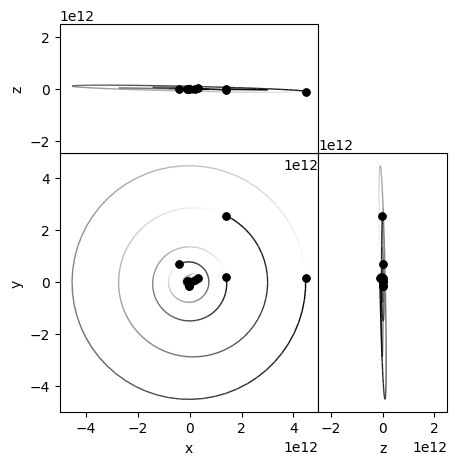

In [ ]:
rb.OrbitPlotSet(sim)

### Estado nominal en la epoca de la covarianza

Para muestrear con $x_k=x_0+L\,z_k$, $x_0$ debe estar en la misma epoca que $C$ (JD 2458929.5). Primero se explica **Time**, que se usa para pasar J2000 a dia juliano. Se toma el estado de 1950 DA que ya se pidio a Horizons en esa fecha, se pasa a heliocentrico restando el estado del Sol y se convierte a los elementos $(e,q,t_p,\Omega,\omega,i)$ con **oscelt** de SPICE. El tiempo de perihelio sale de la anomalia media: $t_p=t_0-M_0/n$, con $n=\sqrt{\mu/a^3}$.

El septimo parametro de la covarianza es $A_2$ (efecto Yarkovsky), en UA/dia$^2$. Su valor nominal se toma de los parametros del modelo de la solucion de SBDB (**model_pars**) y se agrega al final de $x_0$.


In [ ]:
mu_km = mu / 1e9    # mu del sol en km^3/s^2 (mu viene en m^3/s^2)

# j2000 en dias julianos y epoca de la covarianza en segundos desde j2000
f2000 = Time(J2000, format="iso", scale="utc")
et_cov = (epoch_cov - f2000.jd) * dia

# estado de 1950 DA respecto al sol (horizons lo entrega en m y m/s)
X_sol = np.array(datos_horizons["Sol"])
X_1950_DA = np.array(datos_horizons["1950 DA"])
estado_hel = (X_1950_DA - X_sol)/1000    # km y km/s

# elementos orbitales en la epoca de la covarianza
q_2020, e_2020, inc_2020, Omega_2020, omega_2020, M_2020, t0, _ = spy.oscelt(estado_hel, et_cov, mu_km)

# semieje mayor (km), movimiento medio (1/s) y tiempo de perihelio (JD)
a_2020 = q_2020/(1 - e_2020)
n_2020 = np.sqrt(mu_km/a_2020**3)
tp0 = epoch_cov - M_2020/(n_2020 * dia)

# A2 nominal de la solucion de SBDB (UA/dia^2)
A2_nom = 0.0
for par in datos["orbit"]["model_pars"]:
    if par["name"] == "A2":
        A2_nom = float(par["value"])

# x0 = (e, q [UA], tp [JD], node [deg], peri [deg], i [deg], A2 [UA/dia^2])
x0 = np.array([e_2020, q_2020/factor, tp0, Omega_2020*rad, omega_2020*rad, inc_2020*rad, A2_nom])

print(x0)

[ 5.07863988e-01  8.35910624e-01  2.45848193e+06  3.56665418e+02
  2.24679993e+02  1.21678965e+01 -5.27281640e-15]


La funcion **spy.oscelt()** (de SPICE) convierte un vector de estado (posicion y velocidad) en elementos orbitales. Devuelve **rp, ecc, inc, lnode, argp, m0, t0, mu**, con distancias en km, angulos en radianes y tiempos en segundos.

ejemplo:

```python
import spiceypy as spy

mu = 1.327124e11    # km^3/s^2
estado = np.array([1.496e8, 0., 0., 0., 29.78, 0.])    # km y km/s

elementos = spy.oscelt(estado, 0.0, mu)
```

### De elementos a estado para ASSIST

Cada asteroide virtual llega como un vector de elementos $x_k$. Para integrarlo hay que pasarlo a posicion y velocidad: anomalia media $M=n\,(t_0-t_p)$, estado heliocentrico con **conics** (inverso de **oscelt**), suma del estado del Sol para pasar a baricentrico, y rotacion a ecuatorial por la oblicuidad, igual que en la validacion con ASSIST. El septimo elemento, $A_2$, no entra al estado: la funcion lo devuelve para pasarlo a ASSIST. Se comprueba que con $x_0$ se recupera el estado de la celda de validacion.


In [ ]:
def elementos_a_estado(x):
    e_k, q_k, t_peri_k, node_k, peri_k, inc_k, A2_k = x
    q_km_k = q_k*factor    # km
    n_k = np.sqrt(mu_km/(q_km_k/(1 - e_k))**3)    # 1/s
    M0_k = n_k*(epoch_cov - t_peri_k)*dia    # anomalia media en la epoca
    est_hel = spy.conics([q_km_k, e_k, inc_k*deg, node_k*deg, peri_k*deg, M0_k, et_cov, mu_km], et_cov)
    est_bar = est_hel*1000 + X_sol    # baricentrico, ecliptico, SI
    r_eq = ecliptica_a_ecuatorial(est_bar[:3]/AU)    # UA
    v_eq = ecliptica_a_ecuatorial(est_bar[3:]*dia/AU)    # UA/dia
    return r_eq, v_eq, A2_k

# comprobacion: debe coincidir con r0 y v0 de la validacion con ASSIST
r_x0, v_x0, _ = elementos_a_estado(x0)
print(np.linalg.norm(r_x0 - r0)*factor, "km")
print(np.linalg.norm(v_x0 - v0)*AU/dia, "m/s")


0.00012190405232547401 km
8.44395797152201e-09 m/s


La funcion **spy.conics()** (de SPICE) hace el camino inverso de **oscelt**: dados los elementos orbitales y un instante, calcula el vector de estado.

ejemplo:

```python
estado2 = spy.conics(elementos, 0.0)    # km y km/s
```

### Efemerides DE441 y ventana de 2880

Para llegar a 2880 se necesitan las efemerides DE441 (parte 2). La ventana de busqueda del encuentro es marzo de 2880: se integra hasta el 1 de marzo y se avanza hasta el 1 de abril.


In [ ]:
# descarga de las efemerides DE441 parte 2 (cubren el año 2880)
!wget -q https://naif.jpl.nasa.gov/pub/naif/generic_kernels/spk/planets/de441_part-2.bsp

ephem_441 = assist.Ephem("de441_part-2.bsp", de441_n16)

jd_ini = Time("2880-03-01", scale="tdb").jd
jd_fin = Time("2880-04-01", scale="tdb").jd


### Funcion para crear la simulacion de ASSIST

Varias celdas siguientes integran el mismo asteroide con ASSIST. Para no repetir el montaje cada vez, se escribe una funcion que recibe los elementos $x$ y el valor de $A_2$ a usar, y devuelve la simulacion lista junto con el objeto **ex** de ASSIST (hay que conservarlo mientras se usa la simulacion).

In [ ]:
def crear_simulacion(x, A2):
    r_k, v_k, _ = elementos_a_estado(x)
    s = rb.Simulation()
    s.add(x=r_k[0], y=r_k[1], z=r_k[2], vx=v_k[0], vy=v_k[1], vz=v_k[2])
    s.t = epoch_cov - ephem_441.jd_ref
    ex = assist.Extras(s, ephem_441)
    ex.particle_params = np.array([0.0, A2, 0.0])    # [A1, A2, A3] en UA/dia^2
    return s, ex

### Efecto de Yarkovsky

El efecto Yarkovsky es una fuerza no gravitacional: la superficie del asteroide absorbe la luz del Sol y la reemite como calor con un retraso por la rotacion, lo que produce una aceleracion pequeña, casi constante, a lo largo de la orbita. En 850 años esa aceleracion se acumula en un desplazamiento grande. Se modela con la componente transversal $A_2$ del modelo de Marsden, en UA/dia$^2$, que es el septimo parametro de la covarianza. Se pasa a ASSIST con **ex.particle_params** $=[A_1,A_2,A_3]$, con $A_1=A_3=0$.

Para medir su importancia se integra el nominal hasta el inicio de la ventana de 2880 sin $A_2$, con el $A_2$ nominal y con $A_2+1\sigma$, y se compara el desplazamiento de posicion con $R_{\rm ef}\approx8.1\times10^3$ km.


In [ ]:
def posicion_en(x, jd_obj, A2_usado):
    s, ex = crear_simulacion(x, A2_usado)
    s.integrate(jd_obj - ephem_441.jd_ref)
    return np.array(s.particles[0].xyz) # UA

sigma_A2 = np.sqrt(cov[6, 6])

r_sin = posicion_en(x0, jd_ini, 0.0)
r_nom = posicion_en(x0, jd_ini, x0[6])
r_mas = posicion_en(x0, jd_ini, x0[6] + sigma_A2)

dif_nom = np.linalg.norm(r_nom - r_sin)*factor    # km
dif_1s = np.linalg.norm(r_mas - r_nom)*factor     # km

print(f"A2 nominal = {x0[6]:.3e}, sigma = {sigma_A2:.3e} UA/dia^2")
print(f"desplazamiento por A2 nominal: {dif_nom:.3e} km")
print(f"desplazamiento por 1 sigma de A2: {dif_1s:.3e} km")


A2 nominal = -5.273e-15, sigma = 1.039e-15 UA/dia^2
desplazamiento por A2 nominal: 2.082e+07 km
desplazamiento por 1 sigma de A2: 7.997e+06 km


**Resultado.** El $A_2$ nominal ($-5.27\times10^{-15}$ UA/dia$^2$) desplaza la posicion en 2880 unos $2.1\times10^{7}$ km, y $1\sigma$ de $A_2$ ($1.04\times10^{-15}$ UA/dia$^2$) la desplaza unos $8.0\times10^{6}$ km, cerca de 980 veces $R_{\rm ef}$. Ignorar $A_2$ colocaria mal toda la distribucion, y su incertidumbre domina la dispersion en 2880. Por eso $A_2$ se incluye en el modelo y se muestrea con la matriz completa de $7\times7$.


### Integracion del asteroide nominal hasta 2880

Se integra la solucion nominal (con $A_2$) con ASSIST y las efemerides DE441. Se avanza con paso de 0.05 dias dentro de la ventana y, cuando el asteroide entra a una distancia $d_{\rm ref}$ de la Tierra (fuera de su esfera de influencia, 0.01 UA), se calcula el parametro de impacto $b$ con la trayectoria relativa aproximada por una recta (aproximacion de Opik):

$$b=\left|\vec r_{\rm rel}-\frac{\vec r_{\rm rel}\cdot\vec v_{\rm rel}}{|\vec v_{\rm rel}|^2}\,\vec v_{\rm rel}\right|$$

junto con la velocidad relativa $v_\infty$ y la fecha del encuentro. La muestra impacta si $b<R_{\rm ef}$. Si nunca entra a $d_{\rm ref}$, se devuelve $b=\infty$.


In [ ]:
def parametro_impacto(x, d_ref=0.01, paso=0.05):
    s, ex = crear_simulacion(x, x[6])

    s.integrate(jd_ini - ephem_441.jd_ref) # hasta el inicio de la ventana de 2880
    for jd in np.arange(jd_ini, jd_fin, paso):
        s.integrate(jd - ephem_441.jd_ref)
        tierra = ephem_441.get_particle(3, s.t)
        rel = np.array(s.particles[0].xyz) - np.array(tierra.xyz)
        if np.linalg.norm(rel) < d_ref: # entra a d_ref (UA)
            vrel = np.array(s.particles[0].vxyz) - np.array(tierra.vxyz)
            b = np.linalg.norm(rel - np.dot(rel, vrel)/np.dot(vrel, vrel)*vrel)
            v_inf = np.linalg.norm(vrel)*AU/dia/1000    # km/s
            return b*factor, v_inf, jd # km, km/s, JD del encuentro
    return np.inf, np.nan, np.nan # no hubo acercamiento

b_nominal, v_inf_nominal, jd_nominal = parametro_impacto(x0)
print(f"b del nominal = {b_nominal:.3e} km, v_inf = {v_inf_nominal:.2f} km/s")


b del nominal = inf km, v_inf = nan km/s


La funcion **get_particle()** (metodo de **assist.Ephem**) devuelve la particula (posicion y velocidad) de un cuerpo de la efemeride en un instante dado, en dias relativos a **ephem.jd_ref**.

ejemplo:

```python
tierra = ephem.get_particle(3, 0.0)    # 3 = Tierra
tierra.xyz
```

In [ ]:
def acercamiento_minimo(x, jd_a, jd_b, paso=0.5):
    s, ex = crear_simulacion(x, x[6])

    s.integrate(jd_a - ephem_441.jd_ref)
    d_min = np.inf
    jd_min = np.nan
    for jd in np.arange(jd_a, jd_b, paso):
        s.integrate(jd - ephem_441.jd_ref)
        tierra = ephem_441.get_particle(3, s.t)
        rel = np.array(s.particles[0].xyz) - np.array(tierra.xyz)
        d = np.linalg.norm(rel)
        if d < d_min:
            d_min = d
            jd_min = jd
    return d_min*factor, jd_min # km, JD

jd_a = Time("2880-01-01", scale="tdb").jd
jd_b = Time("2880-06-01", scale="tdb").jd

d_min, jd_min = acercamiento_minimo(x0, jd_a, jd_b)
print(f"distancia minima = {d_min:.3e} km ({d_min*1000/AU:.3f} UA)")
print("fecha:", Time(jd_min, format="jd", scale="tdb").iso)

distancia minima = 1.028e+07 km (0.069 UA)
fecha: 2880-03-24 00:00:00.000


### Barrido en A2

La incertidumbre de $A_2$ es la que mas desplaza la posicion en 2880, asi que se barre $A_2$ de $-3\sigma$ a $+3\sigma$ (respecto al nominal) dejando fijos los otros seis elementos. Para cada valor se calcula la distancia minima a la Tierra en la ventana de 2880 y, si el asteroide entra a $d_{\rm ref}$, el parametro de impacto $b$ y $v_\infty$. Como el hueco de impacto ($R_{\rm ef}\approx8.1\times10^3$ km) es mucho mas angosto que el paso del barrido, primero se hace un barrido grueso para ubicar el minimo y luego uno fino alrededor.

Este barrido muestra si, variando solo $A_2$, el asteroide llega a pasar por debajo de $R_{\rm ef}$. No es $P_i$: los otros seis elementos estan fijos en el nominal, y su dispersion tambien cuenta.

In [ ]:
R_Tierra = 6371    # km (radio medio, nasa earth fact sheet)

# ventana ampliada: al variar A2 el encuentro se mueve unos dias
jd_fin = Time("2880-04-15", scale="tdb").jd

def distancia_minima(x, paso=0.5):
    s, ex = crear_simulacion(x, x[6])

    s.integrate(jd_ini - ephem_441.jd_ref)
    d_min = np.inf
    for jd in np.arange(jd_ini, jd_fin, paso):
        s.integrate(jd - ephem_441.jd_ref)
        tierra = ephem_441.get_particle(3, s.t)
        rel = np.array(s.particles[0].xyz) - np.array(tierra.xyz)
        d_min = min(d_min, np.linalg.norm(rel))
    return d_min*factor    # km

def barrido_A2(z_A2):
    d_min = np.zeros(len(z_A2))
    b = np.full(len(z_A2), np.inf)
    v_inf = np.full(len(z_A2), np.nan)
    for k in range(len(z_A2)):
        x_k = x0.copy()
        x_k[6] = x0[6] + z_A2[k]*sigma_A2
        d_min[k] = distancia_minima(x_k)
        if d_min[k] < 2*0.01*factor:    # km, el doble de d_ref de parametro_impacto
            b[k], v_inf[k], _ = parametro_impacto(x_k)
    return d_min, b, v_inf

# barrido grueso: -3 sigma a +3 sigma
z_gruesa = np.linspace(-3, 3, 61)
d_gruesa, b_gruesa, v_gruesa = barrido_A2(z_gruesa)

k_min = np.argmin(d_gruesa)
print(f"minimo grueso: {d_gruesa[k_min]:.3e} km en z = {z_gruesa[k_min]:.2f} sigma")

minimo grueso: 2.438e+05 km en z = 1.60 sigma


La funcion **np.argmin()** devuelve la posicion (el indice) del menor valor de un arreglo.

ejemplo:

```python
np.argmin([5, 2, 7])    # 1
```

La funcion **np.full()** crea un arreglo lleno de un valor dado.

ejemplo:

```python
np.full(3, np.inf)    # array([inf, inf, inf])
```

In [ ]:
# barrido fino alrededor del minimo
z_fina = np.linspace(z_gruesa[k_min] - 0.1, z_gruesa[k_min] + 0.1, 21)
d_fina, b_fina, v_fina = barrido_A2(z_fina)

R_ef_fina = R_Tierra*np.sqrt(1 + (v_esc/v_fina)**2)    # nan donde no hubo acercamiento
impactan_fina = b_fina < R_ef_fina

k_f = np.argmin(b_fina)
print(f"b minimo = {b_fina[k_f]:.3e} km en z = {z_fina[k_f]:.3f} sigma")
print(f"R_ef en ese punto = {R_ef_fina[k_f]:.3e} km")
print(f"{np.sum(impactan_fina)} de {len(z_fina)} valores impactan")

b minimo = 1.507e+04 km en z = 1.650 sigma
R_ef en ese punto = 8.129e+03 km
0 de 21 valores impactan


### Grafica del barrido en $A_2$

Se grafica la distancia minima del barrido grueso y el parametro de impacto $b$ del barrido fino contra el desplazamiento de $A_2$ en sigmas, junto con $R_{\rm ef}$.

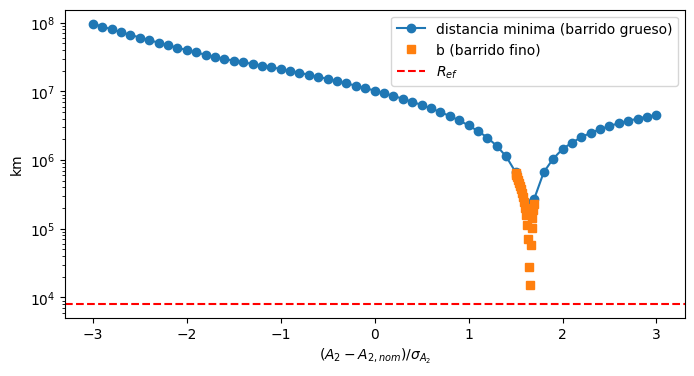

In [ ]:
# grafica hecha con Claude Sonnet 5.5 (Anthropic)
plt.figure(figsize=(8, 4))
plt.semilogy(z_gruesa, d_gruesa, "o-", label="distancia minima (barrido grueso)")
plt.semilogy(z_fina, b_fina, "s", label="b (barrido fino)")
plt.axhline(R_ef_fina[k_f], color="r", linestyle="--", label="$R_{ef}$")
plt.xlabel("$(A_2 - A_{2,nom})/\\sigma_{A_2}$")
plt.ylabel("km")
plt.legend()
plt.show()

### Zoom alrededor del minimo

Se repite el barrido en un intervalo de $\pm0.01\,\sigma$ alrededor del menor $b$ del barrido fino, para ubicar mejor la solucion de impacto.

In [ ]:
# zoom alrededor del minimo del barrido fino
z_zoom = np.linspace(z_fina[k_f] - 0.01, z_fina[k_f] + 0.01, 21)
d_zoom, b_zoom, v_zoom = barrido_A2(z_zoom)

R_ef_zoom = R_Tierra*np.sqrt(1 + (v_esc/v_zoom)**2)
impactan_zoom = b_zoom < R_ef_zoom

k_z = np.argmin(b_zoom)
print(f"b minimo = {b_zoom[k_z]:.3e} km en z = {z_zoom[k_z]:.4f} sigma")
print(f"R_ef en ese punto = {R_ef_zoom[k_z]:.3e} km")
print(f"{np.sum(impactan_zoom)} de {len(z_zoom)} valores impactan")

b minimo = 2.103e+03 km en z = 1.6470 sigma
R_ef en ese punto = 8.129e+03 km
4 de 21 valores impactan


### Solucion de impacto

Con el $A_2$ del zoom donde $b$ es minimo se arma la solucion de impacto $x_{\rm imp}$ y se calculan su $b$, su $v_\infty$, la velocidad de impacto $v_{\rm imp}=\sqrt{v_\infty^2+v_{\rm esc}^2}$ y la fecha del encuentro.

In [ ]:
x_imp = x0.copy()
x_imp[6] = x0[6] + z_zoom[k_z]*sigma_A2

b_imp, v_inf_imp, jd_imp = parametro_impacto(x_imp)
v_imp_2880 = np.sqrt(v_inf_imp**2 + v_esc**2)    # km/s

print(f"b = {b_imp:.3e} km, v_inf = {v_inf_imp:.2f} km/s, v_imp = {v_imp_2880:.2f} km/s")
print("fecha del encuentro:", Time(jd_imp, format="jd", scale="tdb").iso)

b = 2.103e+03 km, v_inf = 14.12 km/s, v_imp = 18.02 km/s
fecha del encuentro: 2880-03-15 19:11:59.995


### Plano B

El plano B es el plano que pasa por el centro de la Tierra y es perpendicular a la velocidad relativa de llegada $\hat s$. La posicion del asteroide en ese plano, $\vec b$, dice que tan cerca pasa: hay impacto si $|\vec b|<R_{\rm ef}$. Con la posicion $\vec r$ y la velocidad $\vec v$ geocentricas en cualquier punto del encuentro (en 2 cuerpos, la Tierra y el asteroide) se obtiene la asintota de llegada:

$$\vec h=\vec r\times\vec v, \qquad \vec e=\frac{\vec v\times\vec h}{\mu_\oplus}-\frac{\vec r}{r}, \qquad v_\infty^2=v^2-\frac{2\mu_\oplus}{r}$$

$$\hat s=\frac{\hat p+\sqrt{e^2-1}\,\hat q}{e}, \qquad \vec b=\frac{\hat s\times\vec h}{v_\infty}, \qquad \hat p=\frac{\vec e}{e}, \quad \hat q=\hat h\times\hat p$$

Como $\vec h$ y $\vec e$ se conservan en el encuentro, $\vec b$ no depende del punto donde se mida. Se mide en el primer paso de 0.05 dias en que la distancia baja de $d_{\rm ref}=0.005$ UA, o en el de distancia minima si nunca baja. El calculo se separa en dos funciones: **acercamiento_geocentrico** integra el asteroide y devuelve su estado geocentrico, y **plano_B** calcula con ese estado la asintota y el vector $\vec b$.

In [ ]:
mu_T = pc.constantes.mu_earth/1e9 # mu de la Tierra en km^3/s^2

def asintota_plano_B(r, v):
    h = np.cross(r, v) # vector de momento angular especifico
    r_n = np.linalg.norm(r) # norma de r (distancia geocentrica)
    v_inf = np.sqrt(np.dot(v, v) - 2*mu_T/r_n) # velocidad hiperbolica en exceso, de la energia: v^2 - 2*mu/r
    e_vec = np.cross(v, h)/mu_T - r/r_n # vector de excentricidad
    e_mag = np.linalg.norm(e_vec) # excentricidad
    p_gorro = e_vec/e_mag # vector unitario que apunta en la direccion del periapsis
    h_gorro = h/np.linalg.norm(h) # vector unitario normal al plano de la orbita
    q_gorro = np.cross(h_gorro, p_gorro) # vector unitario complementario
    s_gorro = (p_gorro + np.sqrt(e_mag**2 - 1)*q_gorro)/e_mag # direccion de la velocidad relativa de llegada (asintota de la hiperbola)
    b_vec = np.cross(s_gorro, h)/v_inf # vector b en el plano B (km)
    return b_vec, s_gorro, v_inf

def acercamiento_geocentrico(x, d_ref=0.005, paso=0.05):
    s, ex = crear_simulacion(x, x[6])

    s.integrate(jd_ini - ephem_441.jd_ref)
    d_min = np.inf
    for jd in np.arange(jd_ini, jd_fin, paso):
        s.integrate(jd - ephem_441.jd_ref)
        tierra = ephem_441.get_particle(3, s.t)
        rel = (np.array(s.particles[0].xyz) - np.array(tierra.xyz))*factor    # km
        d = np.linalg.norm(rel)
        if d < d_min:
            d_min = d
            r_geo = rel
            v_geo = (np.array(s.particles[0].vxyz) - np.array(tierra.vxyz))*AU/dia/1000    # km/s
            jd_enc = jd
        if d < d_ref*factor:
            break
    return r_geo, v_geo, jd_enc

def plano_B(x, d_ref=0.005, paso=0.05):
    r_geo, v_geo, jd_enc = acercamiento_geocentrico(x, d_ref, paso)
    b_vec, s_hat, v_inf = asintota_plano_B(r_geo, v_geo)
    return b_vec, s_hat, v_inf, jd_enc

# base del plano B, perpendicular a s de la solucion de impacto
b_imp3, s_ref, v_inf_ref, jd_enc_ref = plano_B(x_imp)

e1 = np.cross([0, 0, 1], s_ref)
e1 = e1/np.linalg.norm(e1)
e2 = np.cross(s_ref, e1)

def coordenadas_B(b_vec):
    return np.array([np.dot(b_vec, e1), np.dot(b_vec, e2)])

print(f"|b| de la solucion de impacto = {np.linalg.norm(b_imp3):.3e} km, v_inf = {v_inf_ref:.2f} km/s")

|b| de la solucion de impacto = 2.214e+03 km, v_inf = 14.10 km/s


### Linealizacion y covarianza en el plano B

Cerca de la solucion de impacto $x_{\rm imp}$ se aproxima la posicion en el plano B como lineal en los 7 elementos:

$$\vec b(x)\approx\vec b_{\rm imp}+J\,(x-x_{\rm imp}), \qquad J_{\cdot j}=\frac{\vec b(x_{\rm imp}+h_j\hat e_j)-\vec b(x_{\rm imp}-h_j\hat e_j)}{2h_j}$$

con $h_j=0.5\,\sigma_j$. Con la covarianza $C$ de los elementos, la posicion de la solucion nominal en el plano B es gaussiana, con covarianza

$$\Gamma=J\,C\,J^T$$

La probabilidad de impacto es la integral de esa gaussiana sobre el disco de radio $R_{\rm ef}$ centrado en la Tierra:

$$P_i=\int_{|\vec b|<R_{\rm ef}}\mathcal N(\vec b;\ \vec\mu_b,\ \Gamma)\,d^2b$$

El centro $\vec\mu_b$ se calcula de dos maneras: con la linealizacion, $\vec\mu_b=\vec b_{\rm imp}+J\,(x_0-x_{\rm imp})$, y con el $\vec b$ del nominal obtenido por integracion. La diferencia entre ambos mide cuanto falla la linealizacion.

In [ ]:
J = np.zeros((2, 7))
for j in range(7):
    h_j = 0.5*sigma[j]
    x_mas = x_imp.copy()
    x_mas[j] += h_j
    x_menos = x_imp.copy()
    x_menos[j] -= h_j
    b_mas = coordenadas_B(plano_B(x_mas)[0])
    b_menos = coordenadas_B(plano_B(x_menos)[0])
    J[:, j] = (b_mas - b_menos)/(2*h_j)

Gamma = J @ cov @ J.T

# posicion del nominal en el plano B: linealizada y por integracion
mu_lin = coordenadas_B(b_imp3) + J @ (x0 - x_imp)
mu_real = coordenadas_B(plano_B(x0)[0])

print("sigmas del plano B (km):", np.sqrt(np.linalg.eigvalsh(Gamma)))
print("nominal en el plano B, linealizado (km):", mu_lin)
print("nominal en el plano B, integrado (km):", mu_real)

sigmas del plano B (km): [2.62305048e+03 3.96714372e+06]
nominal en el plano B, linealizado (km): [6768049.45239742 2382676.33244478]
nominal en el plano B, integrado (km): [9816172.42888451 3035778.42572672]


### Estimacion de $P_i$ y escala de Palermo

La integral sobre el disco se hace numericamente con una malla cuadrada de $401\times401$ puntos dentro del disco de radio $R_{\rm ef}=R_\oplus\sqrt{1+v_{\rm esc}^2/v_\infty^2}$. Se calcula con los dos valores de $\vec\mu_b$ y se compara con la probabilidad de Sentry ($3.4\times10^{-4}$). La energia usa la velocidad de impacto del encuentro de 2880, y $\Delta T$ es el tiempo desde hoy hasta el encuentro.

In [ ]:
def prob_disco(centro, Gam, R, n=401):
    xs = np.linspace(-R, R, n)
    X, Y = np.meshgrid(xs, xs)
    dentro = X**2 + Y**2 <= R**2
    d = np.stack([X[dentro] - centro[0], Y[dentro] - centro[1]])
    Gam_inv = np.linalg.inv(Gam)
    q = np.einsum("in,ij,jn->n", d, Gam_inv, d)
    densidad = np.exp(-0.5*q)/(2*np.pi*np.sqrt(np.linalg.det(Gam)))
    return densidad.sum()*(xs[1] - xs[0])**2

R_ef = R_Tierra*np.sqrt(1 + (v_esc/v_inf_ref)**2)    # km

P_lin = prob_disco(mu_lin, Gamma, R_ef)
P_real = prob_disco(mu_real, Gamma, R_ef)
print(f"R_ef = {R_ef:.3e} km")
print(f"P_i (nominal linealizado) = {P_lin:.2e}")
print(f"P_i (nominal integrado) = {P_real:.2e}")
print(f"Sentry: {P_sentry:.1e}")

# escala de Palermo con la energia del encuentro de 2880
E_MT_2880 = energia_de_impacto(m, v_imp_2880*1000)/MT_J
t_hoy = Time("2026-11-15", scale="tdb")
d_ref = 0.005    # UA, el mismo d_ref de plano_B
dt_caida = d_ref*factor/v_inf_ref/dia    # dias que tarda en caer de d_ref a la Tierra con v_inf
t_enc = Time(jd_enc_ref + dt_caida, format="jd", scale="tdb")
Delta_T = (t_enc - t_hoy).to_value("yr")

for P in [P_lin, P_real]:
    print(f"PS = {palermo(P, Delta_T, E_MT_2880):.2f}")

R_ef = 8.134e+03 km
P_i (nominal linealizado) = 2.91e-04
P_i (nominal integrado) = 0.00e+00
Sentry: 3.4e-04
PS = -0.95
PS = -inf


/tmp/ipykernel_481/1813276881.py:6: RuntimeWarning: divide by zero encountered in log10
  PS = np.log10(Pi/(frecuencia_fondo(E) * DeltaT))


La funcion **np.meshgrid()** a partir de dos vectores, construye las dos matrices con todas las combinaciones de coordenadas $(x,y)$ de una malla.

ejemplo:

```python
xs = np.linspace(-1, 1, 3)
X, Y = np.meshgrid(xs, xs)

X    # [[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]]
Y    # [[-1, -1, -1], [0, 0, 0], [1, 1, 1]]
```

La funcion **np.stack()** une varios arreglos del mismo tamano en uno nuevo, apilandolos en un eje nuevo.

ejemplo:

```python
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])

np.stack([a, b])    # arreglo de forma (2, 3)
```

La funcion **np.linalg.inv()** calcula la inversa de una matriz.

ejemplo:

```python
np.linalg.inv(np.array([[2., 0.],
                        [0., 4.]]))    # [[0.5, 0], [0, 0.25]]
```

La funcion **np.einsum()** calcula sumas de productos de arreglos con una notacion de indices. Es la forma compacta de escribir un producto de matrices u otra contraccion. En **"in,ij,jn->n"** los indices repetidos se suman y queda un valor por cada columna $n$.

ejemplo:

```python
d = np.array([[1., 2.],
              [0., 1.]])    # dos puntos, uno por columna
M = np.eye(2)

np.einsum("in,ij,jn->n", d, M, d)    # d^T M d para cada columna: [1., 5.]
```

### Ejes principales de $\Gamma$

Se diagonaliza $\Gamma$: los autovalores son las varianzas a lo largo de los ejes de la elipse en el plano B. Se proyecta sobre esos ejes la diferencia entre el nominal integrado y el linealizado.

In [ ]:
w, V = np.linalg.eigh(Gamma)
delta = mu_real - mu_lin
print("sigmas del plano B (km):", np.sqrt(w))
print("desviacion en ejes principales (km):", V.T @ delta)

sigmas del plano B (km): [2.62305048e+03 3.96714372e+06]
desviacion en ejes principales (km): [  395397.82972175 -3092128.16362601]


### Asteroides virtuales utilizados

No se generaron muestras aleatorias de la covarianza. Los asteroides virtuales que se integraron son:

- **El nominal** $x_0$, que no impacta: pasa a $1.03\times10^{7}$ km de la Tierra (0.069 UA) el 24 de marzo de 2880.
- **La solucion de impacto** $x_{\rm imp}$: el nominal con $A_2$ desplazado $+1.647\,\sigma_{A_2}$ (barrido en $A_2$). En el plano B queda a $|\vec b|=2.2\times10^{3}$ km, menor que $R_{\rm ef}$, con $v_\infty=14.1$ km/s y encuentro hacia el 15 de marzo de 2880.
- **Las 14 variaciones** $x_{\rm imp}\pm h_j\hat e_j$, con $h_j=0.5\,\sigma_j$, que dan el Jacobiano $J$ por diferencias centradas.

La covarianza $C$ no se usa para generar orbitas, sino que se lleva al plano B con $\Gamma=JCJ^T$.

### Resultado de $P_i$ y conclusiones

| | Resultado |
|---|---|
| $R_{\rm ef}$ | $8.13\times10^{3}$ km |
| Sigmas de $\Gamma$ en el plano B | $2.6\times10^{3}$ km y $4.0\times10^{6}$ km |
| $P_i$ (linealizado desde $x_{\rm imp}$) | $2.91\times10^{-4}$ |
| $P_i$ (nominal integrado) | $0$ |
| $P_i$ de Sentry | $3.4\times10^{-4}$ |
| Palermo con el $P_i$ linealizado | $-0.95$ |

El $P_i$ linealizado desde $x_{\rm imp}$ es del mismo orden que el de Sentry. Se toma como la estimacion principal porque la integral se evalua cerca de la region de impacto. El valor calculado con el nominal integrado da $0$ (y una Palermo de $-\infty$), porque los dos centros $\vec\mu_b$ difieren unos $3\times10^{6}$ km, mucho mas que el eje angosto de $\Gamma$ ($2.6\times10^{3}$ km). Eso indica que la linealizacion no es valida de manera uniforme, y el resultado depende del punto donde se linealiza.

Limitaciones: solo se exploro una solucion de impacto, no se comprobo la linealizacion con un muestreo y la validacion del modelo se hizo a 6 años.

# Chequeo de la linealizacion

El $P_i$ de la seccion anterior depende de donde se linealiza: con el centro $\vec\mu_b$ integrado da $0$ y con el linealizado desde $x_{\rm imp}$ da $2.9\times10^{-4}$. Para medir cuanto cambia, se repite el calculo linealizando en varios puntos del barrido de $A_2$, desde el nominal ($z=0$) hasta la solucion de impacto ($z=1.647$).

Para un punto base $x_k$ (el nominal con $A_2$ desplazado $z_k\,\sigma_{A_2}$):

1. Se calcula el Jacobiano $J_k$ por diferencias centradas, igual que antes, pero alrededor de $x_k$.
2. Se lleva la covarianza al plano B, $\Gamma_k=J_k\,C\,J_k^T$.
3. El centro es $\vec\mu_k=\vec b(x_k)+J_k\,(x_0-x_k)$, que es la posicion del nominal en el plano B vista desde $x_k$.
4. Se integra la gaussiana sobre el disco con **prob_disco**.

Se usan la misma base $(e_1,e_2)$ del plano B y el mismo $R_{\rm ef}$ de la solucion de impacto, para que los puntos sean comparables. Si $P_i$ cambia en ordenes de magnitud entre puntos, la linealizacion no es confiable. Si se estabiliza, el resultado gana peso.

**Aviso:** cada punto cuesta 15 llamadas a **plano_B** (14 del Jacobiano y 1 de la posicion base), y cada una integra unos 850 años. Puede tardar varios minutos por punto.

In [ ]:
def jacobiano(x_base):
    J_k = np.zeros((2, 7))
    for j in range(7):
        h_j = 0.5*sigma[j]
        x_mas = x_base.copy()
        x_mas[j] += h_j
        x_menos = x_base.copy()
        x_menos[j] -= h_j
        b_mas = coordenadas_B(plano_B(x_mas)[0])
        b_menos = coordenadas_B(plano_B(x_menos)[0])
        J_k[:, j] = (b_mas - b_menos)/(2*h_j)
    return J_k

def prob_linealizada(x_base):
    J_k = jacobiano(x_base)
    Gam_k = J_k @ cov @ J_k.T

    # posicion del punto base en el plano B y centro del nominal visto desde ahi
    b_base = coordenadas_B(plano_B(x_base)[0])
    mu_k = b_base + J_k @ (x0 - x_base)

    P_k = prob_disco(mu_k, Gam_k, R_ef)
    return P_k, mu_k, Gam_k

### Puntos de linealizacion

Se usan $z=0,\ 0.5,\ 1.0$. El punto $z=1.647$ es la solucion de impacto, que ya se calculo antes ($P_i$ linealizado), asi que se reutiliza para no repetir 15 integraciones.

In [ ]:
z_imp = (x_imp[6] - x0[6])/sigma_A2    # sigmas de A2 de la solucion de impacto
z_lista = [0.0, 0.5, 1.0]

z_vals = []
P_vals = []

for z in z_lista:
    x_k = x0.copy()
    x_k[6] = x0[6] + z*sigma_A2

    P_k, mu_k, Gam_k = prob_linealizada(x_k)
    sig_k = np.sqrt(np.linalg.eigvalsh(Gam_k))

    z_vals.append(z)
    P_vals.append(P_k)
    print(f"z = {z:.3f}: P_i = {P_k:.2e}, |mu| = {np.linalg.norm(mu_k):.3e} km, sigmas del plano B = {sig_k} km")

# punto de la solucion de impacto (ya calculado)
z_vals.append(z_imp)
P_vals.append(P_lin)
print(f"z = {z_imp:.3f}: P_i = {P_lin:.2e} (solucion de impacto, calculado antes)")

z = 0.000: P_i = 1.90e-65, |mu| = 1.027e+07 km, sigmas del plano B = [  40434.27246824 8026213.45262618] km
z = 0.500: P_i = 1.13e-42, |mu| = 9.887e+06 km, sigmas del plano B = [  15431.96066586 6443079.80083235] km
z = 1.000: P_i = 2.72e-14, |mu| = 8.897e+06 km, sigmas del plano B = [   6672.86061517 5186922.4417935 ] km
z = 1.647: P_i = 2.91e-04 (solucion de impacto, calculado antes)


### Grafica de $P_i$ contra el punto de linealizacion

Se grafica $P_i$ contra $z$ junto con el valor de Sentry. Donde $P_i=0$ no se puede dibujar en escala logaritmica, y esos puntos se omiten.

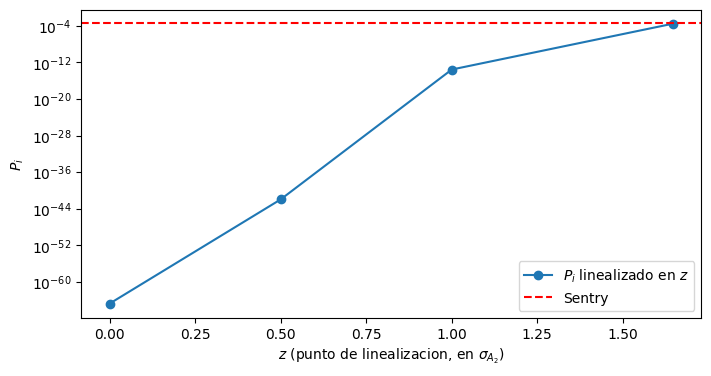

cociente max/min de P_i (solo valores > 0): 1.53e+61


In [ ]:
z_arr = np.array(z_vals)
P_arr = np.array(P_vals)
valido = P_arr > 0

plt.figure(figsize=(8, 4))
plt.semilogy(z_arr[valido], P_arr[valido], "o-", label="$P_i$ linealizado en $z$")
plt.axhline(P_sentry, color="r", linestyle="--", label="Sentry")
plt.xlabel("$z$ (punto de linealizacion, en $\\sigma_{A_2}$)")
plt.ylabel("$P_i$")
plt.legend()
plt.show()

print(f"cociente max/min de P_i (solo valores > 0): {P_arr[valido].max()/P_arr[valido].min():.2e}")

### Sensibilidad a la distancia de referencia $d_{\rm ref}$

**plano_B** mide $\vec b$ con dos cuerpos (solo $\mu_\oplus$) cuando el asteroide baja a $d_{\rm ref}$. Con $d_{\rm ref}=0.005$ UA ($\approx7.5\times10^{5}$ km) el asteroide esta mas lejos que la Luna ($\approx3.8\times10^{5}$ km), cuya gravedad no se incluye en ese calculo. Para ver si importa, se calcula $|\vec b|$ de $x_{\rm imp}$ con tres valores de $d_{\rm ref}$. Si la variacion es de unos cientos de km frente a $R_{\rm ef}\approx8.1\times10^{3}$ km, el efecto es pequeño.

In [ ]:
b_ref005 = np.linalg.norm(plano_B(x_imp, d_ref=0.005)[0])

for d_ref_k in [0.003, 0.005, 0.01]:
    b_k, s_k, v_k, jd_k = plano_B(x_imp, d_ref=d_ref_k)
    b_norma = np.linalg.norm(b_k)
    print(f"d_ref = {d_ref_k} UA: |b| = {b_norma:.4e} km, v_inf = {v_k:.3f} km/s, diferencia con d_ref = 0.005: {b_norma - b_ref005:+.1f} km")

d_ref = 0.003 UA: |b| = 2.2204e+03 km, v_inf = 14.099 km/s, diferencia con d_ref = 0.005: +6.4 km
d_ref = 0.005 UA: |b| = 2.2140e+03 km, v_inf = 14.098 km/s, diferencia con d_ref = 0.005: +0.0 km
d_ref = 0.01 UA: |b| = 2.1058e+03 km, v_inf = 14.099 km/s, diferencia con d_ref = 0.005: -108.1 km


### Resultado del chequeo

El $P_i$ linealizado en distintos puntos del barrido de $A_2$ es $1.9\times10^{-65}$ ($z=0$), $1.1\times10^{-42}$ ($z=0.5$), $2.7\times10^{-14}$ ($z=1.0$) y $2.9\times10^{-4}$ ($z=1.647$). Cambia en decenas de ordenes de magnitud, asi que la linealizacion solo es confiable cerca de la solucion de impacto. Tambien cambian las sigmas del plano B: la del eje angosto pasa de $4.0\times10^{4}$ km en $z=0$ a $2.6\times10^{3}$ km en $z=1.647$. El valor de $2.9\times10^{-4}$ es el del punto donde se linealiza mas cerca de la region de impacto, no un promedio, y que se parezca al de Sentry ($3.4\times10^{-4}$) no basta para validarlo.

Con $d_{\rm ref}=0.003$ y $0.01$ UA, $|\vec b|$ cambia $+6$ km y $-108$ km respecto a $d_{\rm ref}=0.005$ UA ($2214$ km), menos del $5\,\%$ de la sigma angosta del plano B ($2.6\times10^{3}$ km) y cerca del $1\,\%$ de $R_{\rm ef}$. El efecto de no incluir la Luna es pequeño. Con $d_{\rm ref}=0.01$ UA, **plano_B** da casi el mismo $b$ que la aproximacion de Opik ($2.106\times10^{3}$ km frente a $2.103\times10^{3}$ km), asi que la diferencia entre los dos metodos se debe a la distancia en que se mide.

# Cifras que faltaban

Varias cifras del articulo no se imprimen en las celdas anteriores: la energia y el tiempo del encuentro de 2880 se calculan dentro de la celda de $P_i$ pero no se muestran, y los demas valores (cociente con Sentry, suma en cuadratura de errores, desviaciones en sigmas de los ejes de $\Gamma$) se estimaron a mano. Las celdas siguientes los calculan y los imprimen.

### Energia, tiempo y Palermo del encuentro de 2880

Se imprimen **E_MT_2880** y **Delta_T**, que ya existen, y se recalcula la escala de Palermo con el $P_i$ linealizado. Tambien se calcula cuanto cambia $PS$ si la masa cambia $\pm30\,\%$ (por el $\pm10\,\%$ del diametro), con $E\propto m$.

In [ ]:
print(f"E (encuentro de 2880) = {E_MT_2880:.3e} Mt")
print(f"Delta_T = {Delta_T:.2f} años")

PS_lin = palermo(P_lin, Delta_T, E_MT_2880)
print(f"PS con P_i linealizado = {PS_lin:.2f}")

# sensibilidad de PS a la masa (+-30 %), E es proporcional a m
PS_mas = palermo(P_lin, Delta_T, E_MT_2880*1.3)
PS_menos = palermo(P_lin, Delta_T, E_MT_2880*0.7)
print(f"PS con masa +30 % = {PS_mas:.2f}, con masa -30 % = {PS_menos:.2f}")
print(f"variacion de PS = {PS_mas - PS_lin:+.2f} y {PS_menos - PS_lin:+.2f}")

print(f"P_i / P_Sentry = {P_lin/P_sentry:.2f}")

E (encuentro de 2880) = 9.815e+04 Mt
Delta_T = 853.32 años
PS con P_i linealizado = -0.95
PS con masa +30 % = -0.86, con masa -30 % = -1.08
variacion de PS = +0.09 y -0.12
P_i / P_Sentry = 0.86


### Errores de la validacion con REBOUND

Si los errores de la Tierra y de 1950 DA fueran independientes, el error de la posicion relativa seria su suma en cuadratura. Se compara con el error relativo medido (el de la validacion con REBOUND) para ver si los errores se cancelan.

In [ ]:
err_tierra = errores_pos["Tierra"]    # km, de la validacion con REBOUND
err_asteroide = errores_pos["1950 DA"]    # km

err_cuadratura = np.sqrt(err_tierra**2 + err_asteroide**2)
print(f"suma en cuadratura = {err_cuadratura:.0f} km, error relativo medido = {err_relativo:.0f} km")
print(f"cociente medido / cuadratura = {err_relativo/err_cuadratura:.2f}")

suma en cuadratura = 780 km, error relativo medido = 754 km
cociente medido / cuadratura = 0.97


### Importancia de $A_2$ y desviaciones en el plano B

Se compara el desplazamiento de $1\sigma$ de $A_2$ con $R_{\rm ef}$, y se expresa en sigmas de cada eje de $\Gamma$ la diferencia entre el nominal integrado y el linealizado (con **w**, **V** y **delta** de la celda de ejes principales de $\Gamma$).

In [ ]:
print(f"desplazamiento de 1 sigma de A2 / R_ef = {dif_1s/R_ef:.0f}")
print(f"desplazamiento del A2 nominal / R_ef = {dif_nom/R_ef:.0f}")

# desviacion entre nominal integrado y linealizado, en sigmas de cada eje de gamma (w, V y delta vienen de la celda de ejes principales)
print("desviacion en sigmas de cada eje:", (V.T @ delta)/np.sqrt(w))
print(f"|diferencia entre centros| = {np.linalg.norm(delta):.3e} km")

desplazamiento de 1 sigma de A2 / R_ef = 983
desplazamiento del A2 nominal / R_ef = 2560
desviacion en sigmas de cada eje: [150.73969544  -0.77943437]
|diferencia entre centros| = 3.117e+06 km


### Comparacion de los dos metodos para $b$

La aproximacion de Opik (recta, con **parametro_impacto**, d_ref = 0.01 UA) y la asintota de dos cuerpos (con **plano_B**, d_ref = 0.005 UA) deben dar valores parecidos para $x_{\rm imp}$.

In [ ]:
b_plano = np.linalg.norm(b_imp3)
print(f"b (Opik, parametro_impacto) = {b_imp:.4e} km")
print(f"b (dos cuerpos, plano_B)    = {b_plano:.4e} km")
print(f"diferencia = {b_plano - b_imp:+.1f} km, {abs(b_plano - b_imp)/R_ef*100:.1f} % de R_ef")

b (Opik, parametro_impacto) = 2.1029e+03 km
b (dos cuerpos, plano_B)    = 2.2140e+03 km
diferencia = +111.0 km, 1.4 % de R_ef


# Referencias

- Ward, S. N. y Asphaug, E. (2003). Asteroid impact tsunami of 2880 March 16. *Geophysical Journal International*, 153(3), F6-F10. https://doi.org/10.1046/j.1365-246X.2003.01944.x (densidad del asteroide)
- Holman, M. J. et al. (2023). ASSIST: an ephemeris-quality test-particle integrator. *The Planetary Science Journal*, 4, 69 (integracion con ASSIST)
- JPL Small-Body Database, 29075 (1950 DA): https://ssd.jpl.nasa.gov/tools/sbdb_lookup.html#/?sstr=29075 (elementos orbitales, covarianza y parametros fisicos)
- JPL Sentry, 29075 (1950 DA): https://cneos.jpl.nasa.gov/sentry/details.html#?des=29075 (probabilidad de impacto de referencia)
